In [ ]:
# Tester at Frost API fungerer

import requests
from pathlib import Path

# Leser Client ID fra tekstfilen på PC-en din
client_id_file = Path.home() / "frost_client_id.txt"
client_id = client_id_file.read_text().strip()

# Frost API-endepunktet for observasjoner
url = "https://frost.met.no/observations/v0.jsonld"

# Velger værstasjon, tidsperiode og værdata
parameters = {
    "sources": "SN17850",
    "referencetime": "2024-01-01/2024-01-03",
    "elements": "air_temperature"
}

# Sender forespørselen til Frost API
response = requests.get(
    url,
    params=parameters,
    auth=(client_id, ""),
    timeout=30
)

# Viser resultatet av testen
print("Statuskode:", response.status_code)

if response.status_code == 200:
    print("Frost API fungerer!")
    print(response.json()["data"][:1])
else:
    print(response.text[:1000]) 
    



Statuskode: 200
Frost API fungerer!
[{'sourceId': 'SN17850:0', 'referenceTime': '2024-01-01T00:00:00.000Z', 'observations': [{'elementId': 'air_temperature', 'value': -3.7, 'unit': 'degC', 'level': {'levelType': 'height_above_ground', 'unit': 'm', 'value': 1}, 'timeOffset': 'PT0H', 'timeResolution': 'PT1H', 'timeSeriesId': 0, 'performanceCategory': 'C', 'exposureCategory': '1', 'qualityCode': 2}, {'elementId': 'air_temperature', 'value': -3.7, 'unit': 'degC', 'level': {'levelType': 'height_above_ground', 'unit': 'm', 'value': 50}, 'timeOffset': 'PT0H', 'timeResolution': 'PT1H', 'timeSeriesId': 0, 'performanceCategory': 'C', 'exposureCategory': '1', 'qualityCode': 2}, {'elementId': 'air_temperature', 'value': -3.7, 'unit': 'degC', 'level': {'levelType': 'height_above_ground', 'unit': 'm', 'value': 2}, 'timeOffset': 'PT0H', 'timeResolution': 'PT1H', 'timeSeriesId': 0, 'performanceCategory': 'C', 'exposureCategory': '1', 'qualityCode': 0}]}]


# Task 1: Temperature
### Following the example from frost.met.no on how to get the data when using Python

In [17]:
# Requesting the daily mean air temperature for 2025

print("Starting Frost request...")

import requests
from pathlib import Path

# Read Client ID from file
client_id_file = Path.home() / "frost_client_id.txt"
client_id = client_id_file.read_text().strip()

# Frost API endpoint
url = "https://frost.met.no/observations/v0.jsonld"

## Parameters for Ås and all of 2025
parameters = {
    "sources": "SN17850",
    "referencetime": "2025-01-01/2026-01-01",
    "elements": "mean(air_temperature P1D)"
}

# Send request to Frost API
response = requests.get(
    url,
    params=parameters,
    auth=(client_id, ""),
    timeout=30
)

print("Frost response received!")

# Check response status
print("Status code:", response.status_code)

if response.status_code == 200:
    data = response.json()["data"]
    print("Frost API works!")
    print("Number of observations:", len(data))

    ## Extract dates and daily mean temperatures
    dates = []
    temperatures = []

    for item in data:
        dates.append(item["referenceTime"])
        temperatures.append(item["observations"][0]["value"])

    print("Temperatures extracted:", len(temperatures))

else:
    print("Error:", response.text[:1000]) 

Starting Frost request...
Frost response received!
Status code: 200
Frost API works!
Number of observations: 365
Temperatures extracted: 365


## Make plot of air temperature: 

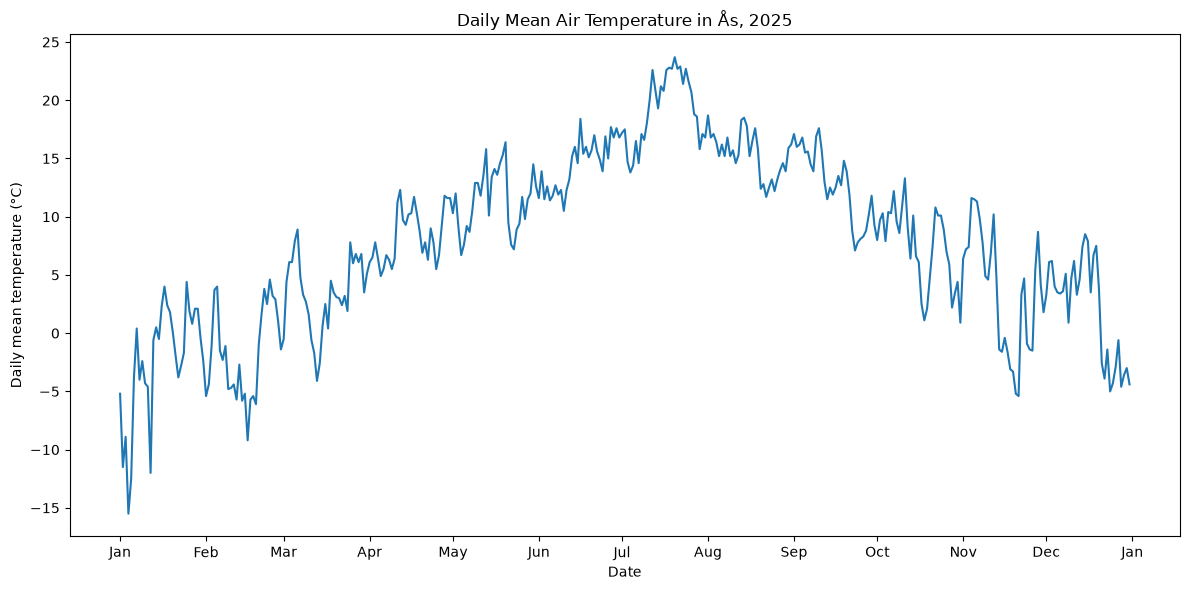

In [18]:
import matplotlib.pyplot as plt

# Plot daily mean temperature for 2025
plt.figure(figsize=(12, 6))
plt.plot(dates, temperatures)

plt.xlabel("Date")
plt.ylabel("Daily mean temperature (°C)")
plt.title("Daily Mean Air Temperature in Ås, 2025")

# Show one date label per month
# --> tried it without this part and the x-axis was very crowded, so I added this to make it more readable 
import matplotlib.dates as mdates

plt.gca().xaxis.set_major_locator(mdates.MonthLocator())
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter("%b"))




plt.tight_layout() #Automatically adjusts the spacing around the graph
plt.show()

## Calculate the mean, median, min and max temperature for this year (2025)

In [19]:
import statistics

## Calculate summary statistics for 2025:
mean_temp = statistics.mean(temperatures)
median_temp = statistics.median(temperatures)
min_temp = min(temperatures)
max_temp = max(temperatures)

## Make the summary table containing the summary statistics

In [20]:
## Display summary table: 

print("Summary of daily mean air temperature in Ås, 2025:")
print("-------------------------------------------------")
print("Mean temperature:", round(mean_temp, 2), "°C")
print("Median temperature:", round(median_temp, 2), "°C")
print("Minimum temperature:", round(min_temp, 2), "°C")
print("Maximum temperature:", round(max_temp, 2), "°C")

Summary of daily mean air temperature in Ås, 2025:
-------------------------------------------------
Mean temperature: 7.87 °C
Median temperature: 8.3 °C
Minimum temperature: -15.5 °C
Maximum temperature: 23.7 °C
